In [85]:
# Import libraries 
import pandas as pd
import numpy as np
import re, io
import os
import matplotlib.pyplot as plt

In [2]:
df_diabetic = pd.read_csv(r"C:\Users\EMMANUELFRANKVICKY\Desktop\Kaggle Datasets\diabetic_data.csv")
df_diabetic.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [3]:
# Check the shape of the dataset
print(df_diabetic.shape)

(101766, 50)


In [4]:
# Check the data types 
print(df_diabetic.dtypes)

encounter_id                 int64
patient_nbr                  int64
race                        object
gender                      object
age                         object
weight                      object
admission_type_id            int64
discharge_disposition_id     int64
admission_source_id          int64
time_in_hospital             int64
payer_code                  object
medical_specialty           object
num_lab_procedures           int64
num_procedures               int64
num_medications              int64
number_outpatient            int64
number_emergency             int64
number_inpatient             int64
diag_1                      object
diag_2                      object
diag_3                      object
number_diagnoses             int64
max_glu_serum               object
A1Cresult                   object
metformin                   object
repaglinide                 object
nateglinide                 object
chlorpropamide              object
glimepiride         

In [5]:
# Check the first row of the dataset
df_diabetic.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [6]:
# Count how many ? each column has, as a percent of all rows. Show it in a small table.
question_pct = (df_diabetic == "?").mean() * 100

question_table = (
    question_pct[question_pct > 0]
    .sort_values(ascending = False)
    .round(2)
    .reset_index()
)

question_table.columns = ["column", "percent_missing"]
question_table

,column,percent_missing
0,weight,96.86
1,medical_specialty,49.08
2,payer_code,39.56
3,race,2.23
4,diag_3,1.40
5,diag_2,0.35
6,diag_1,0.02


In [7]:
# Then reload the file, or replace the ? with real missing values, so pandas can count them.
df_diabetic = df_diabetic.replace("?", np.nan)

In [8]:
# Check that it works
df_diabetic.isna().sum().sort_values(ascending = False).head(10)

weight               98569
max_glu_serum        96420
A1Cresult            84748
medical_specialty    49949
payer_code           40256
race                  2273
diag_3                1423
diag_2                 358
diag_1                  21
encounter_id             0
dtype: int64

In [9]:
# Drop weight, examide and citoglipton. Say why for each.
df_diabetic = df_diabetic.drop(columns=["weight", "examide", "citoglipton"])

In [10]:
# Check that it works
df_diabetic.shape

(101766, 47)

In [11]:
# Decide about payer_code and medical_specialty. They are about 40% and 49% missing. 
cols = ["payer_code", "medical_specialty"]
df_diabetic[cols] = df_diabetic[cols].fillna("Unknown")

In [12]:
# Check that it works 
df_diabetic[cols].isna().sum()
df_diabetic["medical_specialty"].value_counts().head()

medical_specialty
Unknown                   49949
InternalMedicine          14635
Emergency/Trauma           7565
Family/GeneralPractice     7440
Cardiology                 5352
Name: count, dtype: int64

In [13]:
# Quick check that payer_code also worked
df_diabetic[["payer_code", "medical_specialty"]].isna().sum()

payer_code           0
medical_specialty    0
dtype: int64

In [14]:
# Fix race, diag_1, diag_2 and diag_3. Use “Unknown” for race. 
df_diabetic["race"] = df_diabetic["race"].fillna("Unknown")

In [15]:
# Check how many rows are missing in the diagnosis 
df_diabetic[["diag_1", "diag_2", "diag_3"]].isna().sum()

diag_1      21
diag_2     358
diag_3    1423
dtype: int64

In [16]:
# Fill Diagnosis 2 and 3 eith Unknown, and drop the diagnosis 1
df_diabetic["diag_2"] = df_diabetic["diag_2"].fillna("Unknown")
df_diabetic["diag_3"] = df_diabetic["diag_3"].fillna("Unknown")
df_diabetic = df_diabetic.dropna(subset = ["diag_1"])

In [17]:
# Check that diagnosese works 
df_diabetic[["race", "diag_1", "diag_2", "diag_3"]].isna().sum()

race      0
diag_1    0
diag_2    0
diag_3    0
dtype: int64

In [18]:
# Check the counts of the diabetic 
df_diabetic.shape

(101745, 47)

In [19]:
# Fill the blanks in A1Cresult and max_glu_serum with “Not tested”.
cols = ["A1Cresult", "max_glu_serum"]
df_diabetic[cols] = df_diabetic[cols].fillna("Not tested")

In [20]:
# Check if both have been filled with not tested 
df_diabetic[cols].isna().sum()

A1Cresult        0
max_glu_serum    0
dtype: int64

In [21]:
# Check the unique groups in the A1Cresult 
df_diabetic["A1Cresult"].value_counts()

A1Cresult
Not tested    84730
>8             8214
Norm           4989
>7             3812
Name: count, dtype: int64

In [22]:
# Check the gender groups to know which row to remove
df_diabetic["gender"].value_counts()

gender
Female             54703
Male               47039
Unknown/Invalid        3
Name: count, dtype: int64

In [23]:
# Remove the 3 “Unknown/Invalid” gender rows.
df_diabetic = df_diabetic[df_diabetic["gender"] != "Unknown/Invalid"]

In [24]:
# Check the unique groups in the gender column
df_diabetic["gender"].value_counts()

gender
Female    54703
Male      47039
Name: count, dtype: int64

In [25]:
# Deal with repeat patients. Keep only the first visit of each patient (use patient_nbr). 
# Write down how many rows you lost. Reason: if one patient has 10 rows, they count 10 times and make the results look wrong.

rows_before = len(df_diabetic)

df_diabetic = (
    df_diabetic
    .sort_values("encounter_id")
    .drop_duplicates(subset = "patient_nbr", keep = "first")
)

rows_after = len(df_diabetic)
print("Rows Lost:", rows_before - rows_after)

Rows Lost: 30236


In [26]:
# Check if there is any duplicates in the patient_nbr 
df_diabetic["patient_nbr"].duplicated().sum()

np.int64(0)

In [27]:
# Make the target column. Make readmit_30 equal to 1 if readmitted is <30, and 0 for NO and >30. 
df_diabetic["readmit_30"] = (df_diabetic["readmitted"] == "<30").astype(int)

In [28]:
# Check the unique groups in readmi_30
df_diabetic["readmit_30"].value_counts()

readmit_30
0    65215
1     6291
Name: count, dtype: int64

In [29]:
# Check the unique groups in readmitted
df_diabetic["readmitted"].value_counts()

readmitted
NO     42977
>30    22238
<30     6291
Name: count, dtype: int64

In [30]:
df_diabetic["age"].unique()

array(['[80-90)', '[90-100)', '[40-50)', '[50-60)', '[60-70)', '[70-80)',
       '[20-30)', '[10-20)', '[30-40)', '[0-10)'], dtype=object)

In [31]:
# Turn age into a number, for example the middle of each range.
age_map = {
    "[0-10)": 5, "[10-20)": 15, "[20-30)": 25, "[30-40)": 35, "[40-50)": 45, 
    "[50-60)": 55, "[60-70)": 65, "[70-80)": 75, "[80-90)": 85, "[90-100)": 95
}

df_diabetic["age"] = df_diabetic["age"].map(age_map)

In [32]:
# Check if any missing value in the age
df_diabetic["age"].isna().sum()

np.int64(0)

In [33]:
# Check the unique group of the age 
df_diabetic["age"].value_counts().sort_index()

age
5       154
15      535
25     1127
35     2699
45     6876
55    12466
65    15954
75    18208
85    11587
95     1900
Name: count, dtype: int64

In [34]:
# Check that the age column type changed 
df_diabetic["age"].dtypes

dtype('int64')

In [35]:
# Decode the ID columns. Get IDS_mapping.csv from the UCI page (it is not on Kaggle). 
# Join it so you see names, not numbers.

with open(r"C:\Users\EMMANUELFRANKVICKY\Desktop\Kaggle Datasets\IDS_mapping.csv") as f:
    text = f.read().strip()

blocks = re.split(r"\n[,\s]*\n", text)

admission_type   = pd.read_csv(io.StringIO(blocks[0]))
discharge        = pd.read_csv(io.StringIO(blocks[1]))
admission_source = pd.read_csv(io.StringIO(blocks[2]))

print(discharge.head())

   discharge_disposition_id                                        description
0                         1                                 Discharged to home
1                         2  Discharged/transferred to another short term h...
2                         3                      Discharged/transferred to SNF
3                         4                      Discharged/transferred to ICF
4                         5  Discharged/transferred to another type of inpa...


In [36]:
# Merge the IDs with the diabetic dataset
df_diabetic = (
    df_diabetic
    .merge(admission_type.rename(columns = {"description": "admission_type"}), on = "admission_type_id", how = "left")
    .merge(discharge.rename(columns = {"description": "discharge_disposition"}), on = "discharge_disposition_id", how = "left")
    .merge(admission_source.rename(columns = {"description": "admission_source"}), on = "admission_source_id", how = "left")
)

df_diabetic[["admission_type", "discharge_disposition", "admission_source"]].isna().sum()

admission_type           4587
discharge_disposition    2474
admission_source         4949
dtype: int64

In [37]:
# Count number of missing values in the admission type
df_diabetic.loc[df_diabetic["admission_type"].isna(), "admission_type_id"].value_counts()

admission_type_id
6    4587
Name: count, dtype: int64

In [38]:
# Count number of missing values in the discharge disposition
df_diabetic.loc[df_diabetic["discharge_disposition"].isna(), "discharge_disposition_id"].value_counts()

discharge_disposition_id
18    2474
Name: count, dtype: int64

In [39]:
# Count number of missing values in the admission source 
df_diabetic.loc[df_diabetic["admission_source"].isna(), "admission_source_id"].value_counts()

admission_source_id
17    4949
Name: count, dtype: int64

In [40]:
# Check that the number are true for discharge disposition
discharge[discharge["discharge_disposition_id"] == 18]

,discharge_disposition_id,description
17,18,NaN


In [41]:
# Check that the number are true for admission type
admission_type[admission_type["admission_type_id"] == 6]

,admission_type_id,description
5,6,NaN


In [42]:
# Check that the number are true for admission source
admission_source[admission_source["admission_source_id"] == 17]

,admission_source_id,description
15,17,NaN


In [43]:
# Fill the 3 columns with "Not recorded" 
cols = ["admission_type", "admission_source", "discharge_disposition"]
df_diabetic[cols] = df_diabetic[cols].fillna("Not recorded")
df_diabetic[cols].isna().sum()

admission_type           0
admission_source         0
discharge_disposition    0
dtype: int64

In [44]:
# Check how many groups are in admission type
df_diabetic["admission_type"].value_counts()

admission_type
Emergency        36485
Elective         13912
Urgent           13027
Not recorded      4587
Not Available     3174
Not Mapped         291
Trauma Center       21
Newborn              9
Name: count, dtype: int64

In [45]:
# Find the discharges where the patient died or went to hospice.
discharge[discharge["description"].str.contains("Expired|Hospice", case = False, na = False)]

,discharge_disposition_id,description
10,11,Expired
12,13,Hospice / home
13,14,Hospice / medical facility
18,19,"Expired at home. Medicaid only, hospice."
19,20,"Expired in a medical facility. Medicaid only, ..."
20,21,"Expired, place unknown. Medicaid only, hospice."


In [46]:
# Decide, and remove them.
rows_before = len(df_diabetic)

df_diabetic = df_diabetic[
    ~df_diabetic["discharge_disposition"].str.contains("Expired|Hospice", case = False, na = False)
]

print("Rows lost:", rows_before - len(df_diabetic))

Rows lost: 1544


In [47]:
# Group diag_1 into simple groups: Circulatory (390–459), Diabetes (250), 
# Respiratory (460–519), Digestive (520–579), Other. Treat codes starting with V or E as Other.

codes = pd.to_numeric(df_diabetic["diag_1"], errors = "coerce")

conditions = [
    (codes >= 250) & (codes < 251),   # Diabetes
    (codes >= 390) & (codes < 460),   # Circulatory
    (codes >= 460) & (codes < 520),   # Respiratory
    (codes >= 520) & (codes < 580),   # Digestive
]
choices = ["Diabetes", "Circulatory", "Respiratory", "Digestive"]

df_diabetic["diag_1_group"] = np.select(conditions, choices, default = "Other")

In [48]:
# Check that the diag_1_group works
df_diabetic["diag_1_group"].value_counts()

diag_1_group
Other          30126
Circulatory    21317
Respiratory     6446
Digestive       6325
Diabetes        5748
Name: count, dtype: int64

In [49]:
# Check if there is missing values in diag_1_group 
df_diabetic["diag_1_group"].isna().sum()

np.int64(0)

In [50]:
# Check for duplicate rows and strange numbers, then save the clean file as a new CSV.
print("Full duplicate rows:", df_diabetic.duplicated().sum())
print("Repeated encounter_id:", df_diabetic["encounter_id"].duplicated().sum())
print("Repeated patient_nbr:", df_diabetic["patient_nbr"].duplicated().sum())

Full duplicate rows: 0
Repeated encounter_id: 0
Repeated patient_nbr: 0


In [51]:
# Check for strange numbers 
num_cols = df_diabetic.select_dtypes(include = "number").columns
df_diabetic[num_cols].describe().T[["min", "max", "mean"]]

,min,max,mean
encounter_id,12522.0,443867222.0,1.566321e+08
patient_nbr,135.0,189502619.0,5.493904e+07
age,5.0,95.0,6.544010e+01
admission_type_id,1.0,8.0,2.107072e+00
discharge_disposition_id,1.0,28.0,3.412095e+00
admission_source_id,1.0,25.0,5.636631e+00
time_in_hospital,1.0,14.0,4.273391e+00
num_lab_procedures,1.0,132.0,4.287676e+01
num_procedures,0.0,6.0,1.425602e+00
num_medications,1.0,81.0,1.566540e+01


In [52]:
# Check for any negative numbers 
(df_diabetic[num_cols] < 0).sum()

encounter_id                0
patient_nbr                 0
age                         0
admission_type_id           0
discharge_disposition_id    0
admission_source_id         0
time_in_hospital            0
num_lab_procedures          0
num_procedures              0
num_medications             0
number_outpatient           0
number_emergency            0
number_inpatient            0
number_diagnoses            0
readmit_30                  0
dtype: int64

In [53]:
# Save the clean dataset as CSV file 
df_diabetic.to_csv("diabetic_data_clean.csv", index = False)

In [54]:
# Check that it works 
check = pd.read_csv("diabetic_data_clean.csv")
print(check.shape, df_diabetic.shape)

(69962, 52) (69962, 52)


In [55]:
# Compare the original dataset with the cleaned dataset
raw = pd.read_csv(r"C:\Users\EMMANUELFRANKVICKY\Desktop\Kaggle Datasets\diabetic_data.csv")
print("Messy:", raw.shape)
print("Clean:", df_diabetic.shape)

Messy: (101766, 50)
Clean: (69962, 52)


In [56]:
# What percent of patients were readmitted within 30 days? 
readmit_pct = df_diabetic["readmit_30"].mean() * 100
print(round(readmit_pct, 2), "%")

8.97 %


In [57]:
# Which age group has the highest 30-day readmission?
highest_readmit = (
    df_diabetic.groupby("age")["readmit_30"]
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending = False)
)

highest_readmit

age
85    10.77
75    10.24
95     9.55
65     9.00
25     7.40
45     7.40
55     7.12
35     6.98
15     4.87
5      1.96
Name: readmit_30, dtype: float64

In [58]:
# Check the highest count and pct of the patient age readmitted
df_diabetic.groupby("age")["readmit_30"].agg(["count", "mean"])

,count,mean
age,,
5,153,0.019608
15,534,0.048689
25,1121,0.074041
35,2692,0.069837
45,6826,0.073982
55,12349,0.071180
65,15679,0.089993
75,17748,0.102378
85,11100,0.107658


In [59]:
# Does gender or race matter?
gender_rate = (
    df_diabetic.groupby("gender")["readmit_30"]
    .agg(["count", "mean"])
)
gender_rate["mean"] = (gender_rate["mean"] * 100).round(2)
gender_rate 

,count,mean
gender,,
Female,37227,9.03
Male,32735,8.90


In [60]:
# Does race matter? 
race_rate = (
    df_diabetic.groupby("race")["readmit_30"]
    .agg(["count", "mean"])
)
race_rate["mean"] = (race_rate["mean"] * 100).round(2)
race_rate.sort_values("mean", ascending = False)

,count,mean
race,,
Caucasian,52290,9.18
AfricanAmerican,12622,8.66
Asian,488,8.40
Hispanic,1498,8.01
Unknown,1915,7.36
Other,1149,6.88


In [61]:
# Does a longer stay (time_in_hospital) mean more readmission?
longer_hospital_stay = (
    df_diabetic.groupby("time_in_hospital")["readmit_30"]
    .agg(["count", "mean"])
)
longer_hospital_stay["mean"] = (longer_hospital_stay["mean"] * 100).round(2)
longer_hospital_stay.sort_index()

,count,mean
time_in_hospital,,
1,10467,6.54
2,12177,7.66
3,12484,8.19
4,9420,8.84
5,6697,9.77
6,5050,10.89
7,3903,11.43
8,2841,12.32
9,1911,12.30


In [62]:
# Does number_inpatient (earlier hospital stays in the last year) relate to readmission? 
earlier_patients = (
    df_diabetic.groupby("number_inpatient")["readmit_30"]
    .agg(["count", "mean"])
)
earlier_patients["mean"] = (earlier_patients["mean"] * 100).round(2)
earlier_patients.sort_index()

,count,mean
number_inpatient,,
0,61770,8.12
1,5796,12.89
2,1501,18.52
3,462,23.59
4,228,23.68
5,102,28.43
6,55,40.00
7,19,47.37
8,13,23.08


In [63]:
# Do the same for number_emergency.
emergency_patients = (
    df_diabetic.groupby("number_emergency")["readmit_30"]
    .agg(["count", "mean"])
)
emergency_patients["mean"] = (emergency_patients["mean"] * 100).round(2)
emergency_patients.sort_index()

,count,mean
number_emergency,,
0,64863,8.73
1,3881,11.23
2,789,13.43
3,242,12.81
4,95,24.21
5,32,15.62
6,26,23.08
7,8,12.50
8,9,22.22


In [64]:
# Which admission types and discharge types have the highest readmission?
admin_patient_type = (
    df_diabetic.groupby("admission_type")["readmit_30"]
    .agg(["count", "mean"])
)
admin_patient_type["mean"] = (admin_patient_type["mean"] * 100).round(2)
admin_patient_type.sort_index()

,count,mean
admission_type,,
Elective,13780,8.28
Emergency,35461,9.16
Newborn,9,11.11
Not Available,3086,8.55
Not Mapped,291,7.22
Not recorded,4515,9.97
Trauma Center,18,0.00
Urgent,12802,8.97


In [65]:
# Which discharge types have the highest readmission?
discharge_patient_type = (
    df_diabetic.groupby("discharge_disposition")["readmit_30"]
    .agg(["count", "mean"])
)
discharge_patient_type["mean"] = (discharge_patient_type["mean"] * 100).round(2)
discharge_patient_type.sort_index()

,count,mean
discharge_disposition,,
Admitted as an inpatient to this hospital,9,22.22
Discharged to home,44313,6.95
Discharged/transferred to ICF,541,10.35
Discharged/transferred to SNF,8782,13.38
Discharged/transferred to a federal health care facility.,3,0.00
Discharged/transferred to a long term care hospital.,260,3.08
Discharged/transferred to a nursing facility certified under Medicaid but not certified under Medicare.,25,4.00
Discharged/transferred to another rehab fac including rehab units of a hospital .,1409,26.33
Discharged/transferred to another short term hospital,1538,13.72


In [66]:
# Which diagnosis group has the highest readmission?
patients_diagnosis = (
    df_diabetic.groupby("diag_1_group")["readmit_30"]
    .agg(["count", "mean"])
)
patients_diagnosis["mean"] = (patients_diagnosis["mean"] * 100).round(2)
patients_diagnosis.sort_index()

,count,mean
diag_1_group,,
Circulatory,21317,9.69
Diabetes,5748,9.12
Digestive,6325,7.94
Other,30126,8.79
Respiratory,6446,8.32


In [67]:
# Does a medication change (change) or an A1C test (A1Cresult) relate to readmission? (A1C is a blood sugar test.)
change_rates = (
    df_diabetic.groupby("change")["readmit_30"]
    .agg(["count", "mean"])
)
change_rates["mean"] = (change_rates["mean"] * 100).round(2)
change_rates.sort_index()

,count,mean
change,,
Ch,31484,9.43
No,38478,8.59


In [68]:
# Does an A1C test (A1Cresult) relate to readmission? (A1C is a blood sugar test.)
a1c_rates = (
    df_diabetic.groupby("A1Cresult")["readmit_30"]
    .agg(["count", "mean"])
)
a1c_rates["mean"] = (a1c_rates["mean"] * 100).round(2)
a1c_rates.sort_values("mean", ascending = False)

,count,mean
A1Cresult,,
Not tested,57120,9.10
Norm,3740,8.61
>7,2865,8.59
>8,6237,8.16


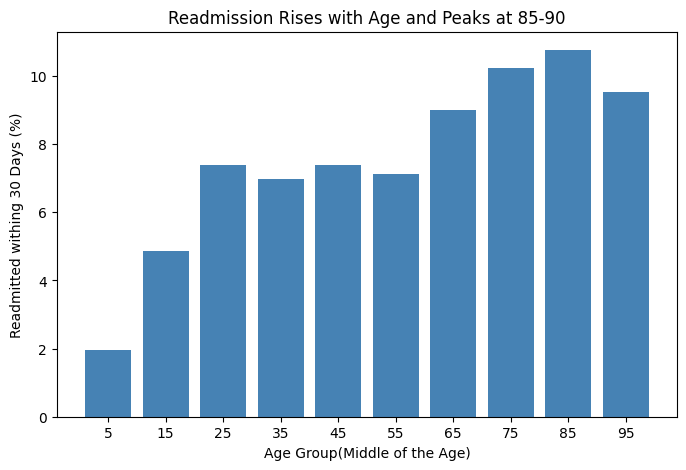

In [87]:
# 1. Work out the readmission rate for each group
rates = df_diabetic.groupby("age")["readmit_30"].mean() * 100

# 2. Draw the bars
plt.figure(figsize = (8, 5))
plt.bar(rates.index.astype(str), rates.values, color = "steelblue")

# 3. Add the title and labels
plt.title("Readmission Rises with Age and Peaks at 85-90")
plt.xlabel("Age Group(Middle of the Age)")
plt.ylabel("Readmitted withing 30 Days (%)")
           
# 4. Show it
plt.savefig(r"C:\Users\EMMANUELFRANKVICKY\Downloads\Python_Charts\age.png", dpi=150, bbox_inches="tight")
plt.show()

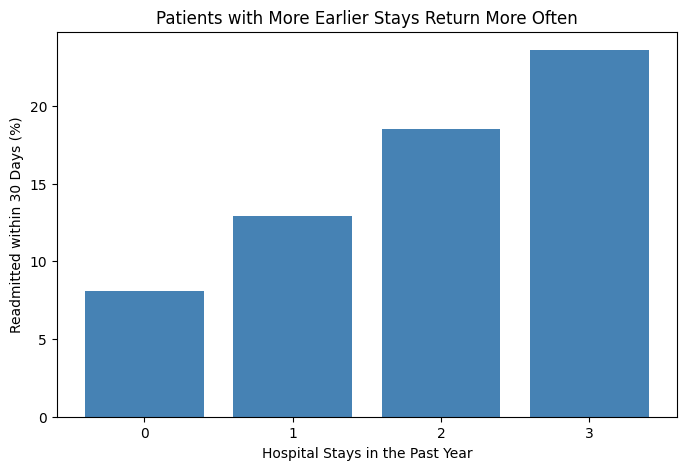

In [88]:
# 1. Work out the number of inpatient
small = df_diabetic[df_diabetic["number_inpatient"] <= 3]
rates = small.groupby("number_inpatient")["readmit_30"].mean() * 100

# 2. Draw the bars
plt.figure(figsize = (8, 5))
plt.bar(rates.index.astype(str), rates.values, color = "steelblue")

# 3. Add the title and labels
plt.title("Patients with More Earlier Stays Return More Often")
plt.xlabel("Hospital Stays in the Past Year")
plt.ylabel("Readmitted within 30 Days (%)")

# 4. Show it
plt.savefig(r"C:\Users\EMMANUELFRANKVICKY\Downloads\Python_Charts\inpatient.png", dpi=150, bbox_inches="tight")
plt.show()

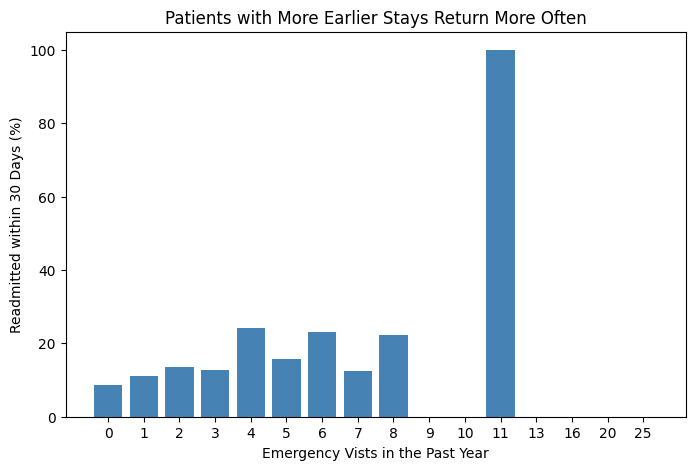

In [89]:
# 1. Work out the readmission rate for each group
small = df_diabetic[df_diabetic["number_emergency"] <= 30]
rates = small.groupby("number_emergency")["readmit_30"].mean() * 100

# 2. Draw the bars
plt.figure(figsize = (8, 5))
plt.bar(rates.index.astype(str), rates.values, color = "steelblue")

# 3. Add the title and labels
plt.title("Patients with More Earlier Stays Return More Often")
plt.xlabel("Emergency Vists in the Past Year")
plt.ylabel("Readmitted within 30 Days (%)")

# 4. Show it
plt.savefig(r"C:\Users\EMMANUELFRANKVICKY\Downloads\Python_Charts\emergency.png", dpi=150, bbox_inches="tight")
plt.show()

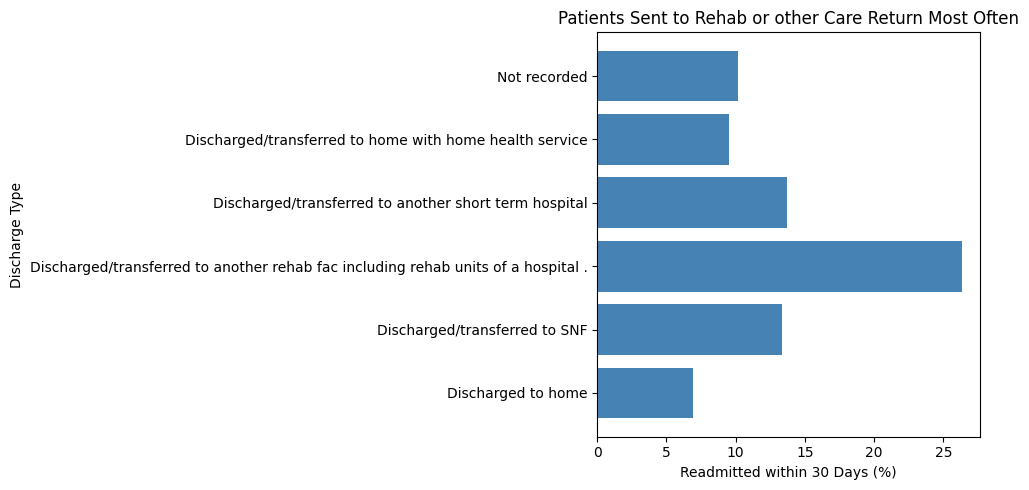

In [90]:
# 1. Work out the readmission rates for discharge disposition
big = df_diabetic["discharge_disposition"].value_counts()
big = big[big > 1000].index
data = df_diabetic[df_diabetic["discharge_disposition"].isin(big)]
rates = data.groupby("discharge_disposition")["readmit_30"].mean() * 100

# 2. Draw the bars
plt.figure(figsize = (10, 5))
plt.barh(rates.index, rates.values, color = "steelblue")

# 3. Add the title and labels
plt.title("Patients Sent to Rehab or other Care Return Most Often")
plt.xlabel("Readmitted within 30 Days (%)")
plt.ylabel("Discharge Type")
plt.tight_layout()

# 4. Show it
plt.savefig(r"C:\Users\EMMANUELFRANKVICKY\Downloads\Python_Charts\discharge_disposition.png", dpi=150, bbox_inches="tight")
plt.show()

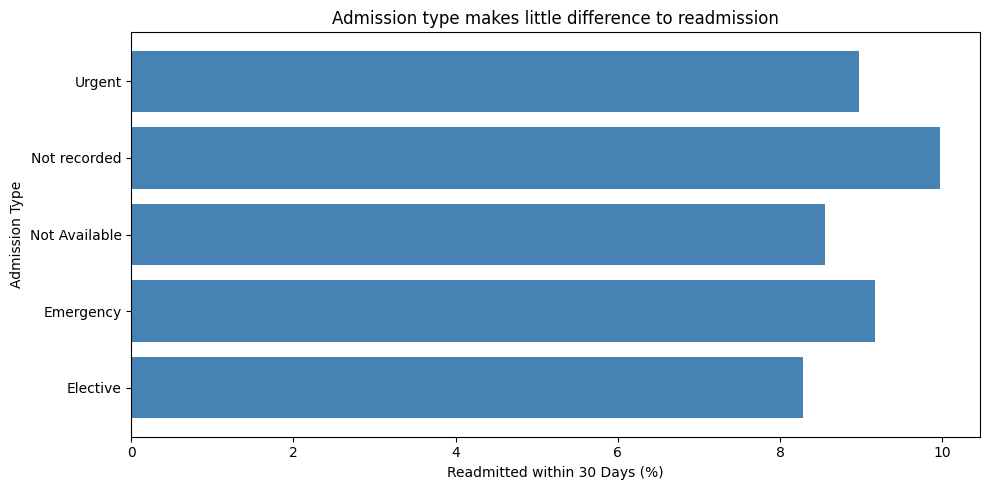

In [91]:
# 1. Work out the readmission rates for discharge type 
big = df_diabetic["admission_type"].value_counts()
big = big[big > 1000].index
data = df_diabetic[df_diabetic["admission_type"].isin(big)]
rates = data.groupby("admission_type")["readmit_30"].mean() * 100

# 2. Draw the bars
plt.figure(figsize = (10, 5))
plt.barh(rates.index, rates.values, color = "steelblue")

# 3. Add the title and labels
plt.title("Admission type makes little difference to readmission")
plt.xlabel("Readmitted within 30 Days (%)")
plt.ylabel("Admission Type")
plt.tight_layout()

# 4. Show it
plt.savefig(r"C:\Users\EMMANUELFRANKVICKY\Downloads\Python_Charts\admission_type.png", dpi=150, bbox_inches="tight")
plt.show()

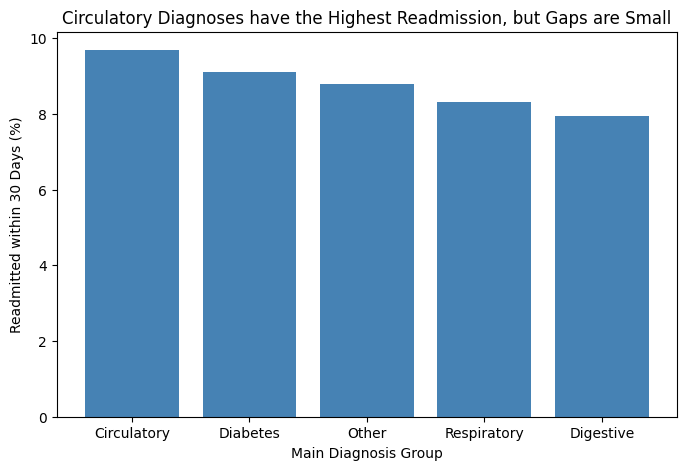

In [92]:
# 1. Work out the readmission rates for diagnosis group
rates = df_diabetic.groupby("diag_1_group")["readmit_30"].mean() * 100
rates = rates.sort_values(ascending = False)

# 2. Draw the bars
plt.figure(figsize = (8, 5))
plt.bar(rates.index, rates.values, color = "steelblue")

# 3. Add the title and labels
plt.title("Circulatory Diagnoses have the Highest Readmission, but Gaps are Small")
plt.xlabel("Main Diagnosis Group")
plt.ylabel("Readmitted within 30 Days (%)")

# 4. Show it
plt.savefig(r"C:\Users\EMMANUELFRANKVICKY\Downloads\Python_Charts\diagnosis.png", dpi=150, bbox_inches="tight")
plt.show()